# Review of approved experiments 1, 3 and 5

All comparisons below use the same original A validation breaths and native
inspiratory pressure units. The official Gym score .18550 belongs to the earlier
all-data submission. It is a separate measurement from this validation table.

This notebook reviews saved artifacts only. It never trains, updates a model,
changes a split, generates a submission or contacts external services. The audit
recomputes predictions' metrics, grouping and artifact identities independently.


In [1]:
from pathlib import Path
import json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
PROJECT=Path.cwd().resolve();OUT=PROJECT/'outputs/approved_experiments_v007';REVIEW=OUT/'review';REVIEW.mkdir(parents=True,exist_ok=True)
AUDIT_PATH=PROJECT/'research/screen_review_v007.json';audit=json.loads(AUDIT_PATH.read_text())
failures=[c for c in audit['checks'] if not c.get('passed',c.get('ok',True))]
assert not failures,failures
print('Audit:',audit['status'],'| checks:',len(audit['checks']),'| generated UTC:',audit['audit_time_utc'])
print('Whole batch complete:',audit['screen_complete'])
print('Missing completed candidates:',audit['missing_candidate_records'])


Audit: complete_verified | checks: 199 | generated UTC: 2026-11-05T06:00:04.531370+00:00
Whole batch complete: True
Missing completed candidates: []


In [2]:
labels={'correction_gamma_0p0':'Original ensemble / zero correction','correction_gamma_0p5':'Residual correction, half strength','correction_gamma_1p0':'Residual correction, full strength','pressure_levels':'Pressure-level probability model','regularization_adamw_1e4':'Deep LSTM, AdamW decay 0.0001','regularization_dropout_025':'Deep LSTM, dropout 0.25'}
rows=[]
for c in audit['candidates']:
    record=json.loads((OUT/('record_A_'+c['name']+'.json')).read_text())
    rows.append(dict(candidate=labels.get(c['name'],c['name']),individual_A_MAE=c['individual_A_MAE'],ensemble_A_MAE=c['pair_A_MAE'],median_absolute_error=c['median_absolute_error'],p90_absolute_error=c['p90_absolute_error'],improvement=c['gain'],eligible=c['eligible'],new_fit_minutes=record['elapsed_seconds']/60,OOF_minutes=record.get('OOF_training_seconds',0)/60,best_epoch=record.get('best_epoch')))
table=pd.DataFrame(rows).sort_values('ensemble_A_MAE');display(table.style.format(precision=6));table.to_csv(REVIEW/'verified_screen_table.csv',index=False)
print('Eligibility requires at least .003 lower ensemble MAE and a paired-bootstrap upper95 bound below zero.')

print('Correction strengths share the same OOF base fits and calibrator; their repeated times are not separate training costs.')


Eligibility requires at least .003 lower ensemble MAE and a paired-bootstrap upper95 bound below zero.
Correction strengths share the same OOF base fits and calibrator; their repeated times are not separate training costs.


,candidate,individual_A_MAE,ensemble_A_MAE,median_absolute_error,p90_absolute_error,improvement,eligible,new_fit_minutes,OOF_minutes,best_epoch
0,"Residual correction, full strength",0.212302,0.195584,0.100364,0.426725,0.000979,False,1.416291,69.338467,nan
1,"Residual correction, half strength",0.212672,0.195912,0.100582,0.427353,0.000650,False,1.416291,69.338467,nan
2,Original ensemble / zero correction,0.214166,0.196563,0.100946,0.428331,0.000000,False,1.416291,69.338467,nan
3,"Deep LSTM, AdamW decay 0.0001",0.214671,0.198516,0.101002,0.432709,-0.001954,False,136.939099,0.000000,197.000000
4,"Deep LSTM, dropout 0.25",0.220789,0.201479,0.102364,0.433394,-0.004916,False,139.063080,0.000000,194.000000
5,Pressure-level probability model,0.234494,0.204355,0.103607,0.454291,-0.007792,False,74.251465,0.000000,193.000000


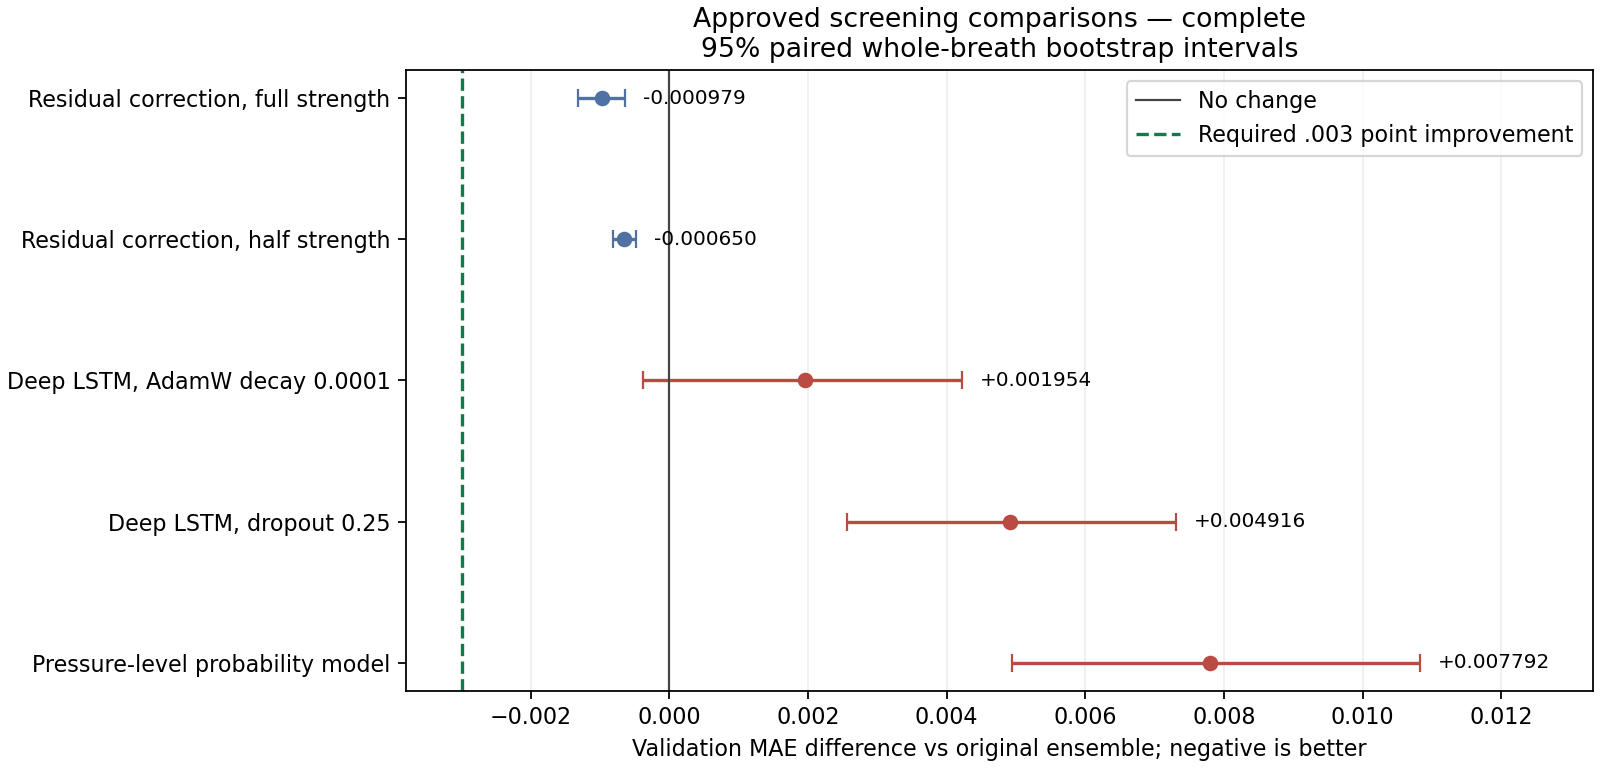

In [3]:
comp=[c for c in audit['candidates'] if c['name']!='correction_gamma_0p0']
comp=sorted(comp,key=lambda c:c['interval']['difference'])
fig,ax=plt.subplots(figsize=(10,4.8),layout='constrained')
for i,c in enumerate(comp):
    ci=c['interval'];m=ci['difference'];lo=ci['bootstrap_95_low'];hi=ci['bootstrap_95_high']
    color='#16784b' if c['eligible'] else ('#b94b42' if m>0 else '#5072a2')
    ax.errorbar(m,i,xerr=np.array([[m-lo],[hi-m]]),fmt='o',capsize=4,color=color)
    ax.annotate(f'{m:+.6f}',(hi,i),xytext=(8,0),textcoords='offset points',va='center',fontsize=9)
ax.axvline(0,color='#444444',linewidth=1,label='No change')
ax.axvline(-.003,color='#16784b',linestyle='--',label='Required .003 point improvement')
ax.set_yticks(range(len(comp)),[labels[c['name']] for c in comp]);ax.invert_yaxis()
ax.set_xlabel('Validation MAE difference vs original ensemble; negative is better')
ax.set_title('Approved screening comparisons — '+('complete' if audit['screen_complete'] else 'partial')+'\n95% paired whole-breath bootstrap intervals',fontsize=12)
ax.set_xlim(-.0038,max(c['interval']['bootstrap_95_high'] for c in comp)+.0025)
ax.grid(axis='x',alpha=.2);ax.legend(loc='upper right')
fig.savefig(REVIEW/'paired_validation_differences.png',dpi=160);fig.savefig(REVIEW/'paired_validation_differences.svg');plt.close(fig);display(Image(filename=str(REVIEW/'paired_validation_differences.png')))


In [4]:
base=pd.read_csv(OUT/'A_correction_gamma_0p0_pair_by_rc.csv');corrected=pd.read_csv(OUT/'A_correction_gamma_1p0_pair_by_rc.csv')
by=base.merge(corrected,on=['R','C'],suffixes=('_baseline','_corrected'));by['absolute_error_reduction']=by.total_absolute_error_baseline-by.total_absolute_error_corrected
summary=by.groupby('R').absolute_error_reduction.sum().to_frame();summary['share_of_net_reduction']=summary.absolute_error_reduction/summary.absolute_error_reduction.sum();display(summary)
summary.to_csv(REVIEW/'residual_correction_total_error_reduction_by_R.csv')
print('A larger share of the small correction gain comes from R=50; this does not establish a large overall improvement.')


A larger share of the small correction gain comes from R=50; this does not establish a large overall improvement.


,absolute_error_reduction,share_of_net_reduction
R,,
5,17.064776,0.084586
20,60.167039,0.298235
50,124.512162,0.617179


## Interpretation and decision

The full-strength correction gives a small, consistent improvement on A. Its
native ensemble mean error is about .195584 versus .196563, a .50% reduction.
Its median individual point error is about .100364 versus .100946. These are
validation measurements, not new official submission scores.

The pressure-level package is worse under this recipe even though all validation
pressure levels are present in the training-only codebook. Missing label support
does not explain that result. The tested weight decay shows no demonstrated
improvement. A failed recipe is not evidence that every alternative in that
method family will fail.

The complete batch passed 199 independent checks. No candidate meets the frozen
minimum .003 MAE improvement. Dropout .25 also worsened pair MAE to .201479.
No candidate was promoted, fitted on all data, or submitted. The existing
accepted .18550 CSV remains the official best. Grouped confirmation is required for a
qualifying candidate; repeated A selection is not an unbiased performance estimate.
